<a href="https://colab.research.google.com/github/Gloou-ui/NM/blob/main/%D0%9B%D0%A010_%D0%9B%D0%B8%D1%82%D0%B2%D0%B8%D0%BD_%D0%A4%D0%86%D0%A23_10_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Литвин Мирослав   
**Група:** ФІТ3-10  
**Дата:** 20.11.2026 18:30

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: []


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "Футболка/топ", "Штани", "Светр", "Сукня", "Пальто",
    "Сандалі", "Сорочка", "Кросівки", "Сумка", "Черевики"
]

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)
print("Кількість класів:", len(class_names))


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)
Кількість класів: 10


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

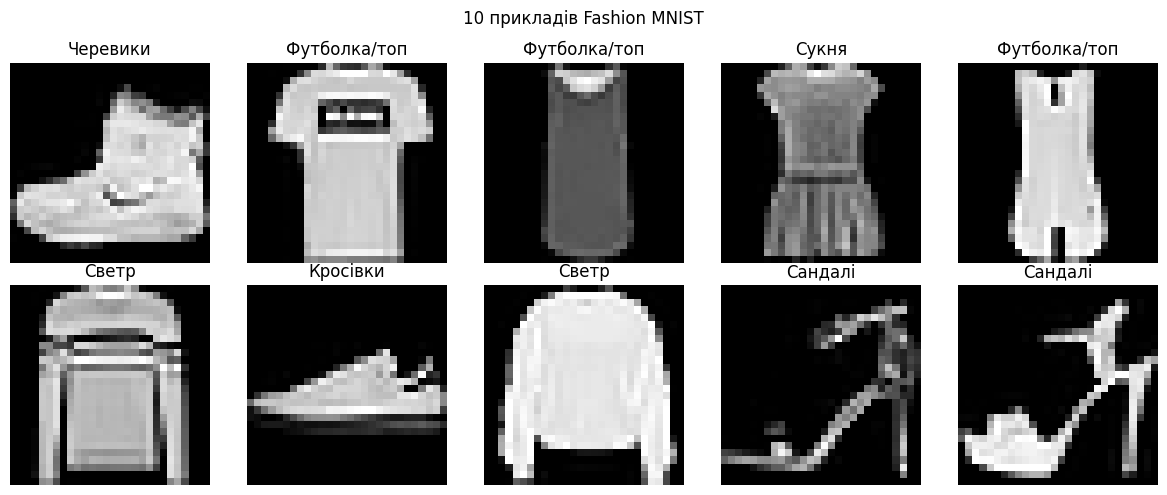

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(class_names[int(y_train[i])])
    ax.axis("off")
plt.suptitle("10 прикладів Fashion MNIST")
plt.tight_layout()
plt.show()


### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Тип даних:", x_train.dtype)
print("Діапазон x_train:", float(x_train.min()), "-", float(x_train.max()))
print("Діапазон x_test:", float(x_test.min()), "-", float(x_test.max()))


Тип даних: float32
Діапазон x_train: 0.0 - 1.0
Діапазон x_test: 0.0 - 1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.20),
    layers.Dense(10, activation="softmax")
], name="Fashion_MNIST_baseline")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

print("Обґрунтування: два приховані шари на 256 і 128 нейронів дають змогу моделі вивчати ознаки різної складності.")
print("Dropout зменшує перенавчання, а learning_rate=0.001 є поширеним початковим значенням для Adam.")


Model: "Fashion_MNIST_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Обґрунтування: два приховані шари на 256 і 128 нейронів дають змогу моделі вивчати ознаки різної складності.
Dropout зменшує перенавчання, а learning_rate=0.001 є поширеним початковим значенням для Adam.


### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
early_stopping = EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
)

history = model.fit(
    x_train, y_train,
    epochs=30,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)


Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7776 - loss: 0.6239 - val_accuracy: 0.8426 - val_loss: 0.4242 - learning_rate: 0.0010
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8421 - loss: 0.4379 - val_accuracy: 0.8487 - val_loss: 0.3991 - learning_rate: 0.0010
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8552 - loss: 0.3983 - val_accuracy: 0.8621 - val_loss: 0.3757 - learning_rate: 0.0010
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8632 - loss: 0.3718 - val_accuracy: 0.8610 - val_loss: 0.3652 - learning_rate: 0.0010
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8709 - loss: 0.3543 - val_accuracy: 0.8753 - val_loss: 0.3419 - learning_rate: 0.0010
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8744 - loss: 0.3389 - val_accuracy: 0.8736 - val_loss: 0.3384 - learning_rate: 0.0010
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8789 - loss: 0.32

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
model.summary()
print("Кількість шарів:", len(model.layers))
print("Загальна кількість параметрів:", model.count_params())


Model: "Fashion_MNIST_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів: 6
Загальна кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
model_save_path = "/content/fashion_mnist_baseline.keras"
model.save(model_save_path)
print("Модель збережено:", model_save_path)


Модель збережено: /content/fashion_mnist_baseline.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

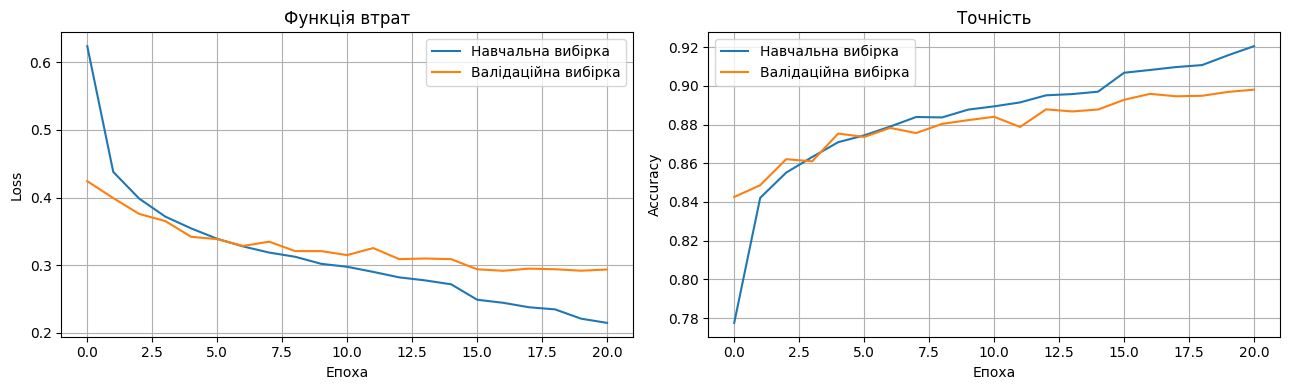

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["loss"], label="Навчальна вибірка")
axes[0].plot(history.history["val_loss"], label="Валідаційна вибірка")
axes[0].set_title("Функція втрат")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["accuracy"], label="Навчальна вибірка")
axes[1].plot(history.history["val_accuracy"], label="Валідаційна вибірка")
axes[1].set_title("Точність")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print("\\nКласифікаційний звіт:")
print(classification_report(
    y_test, y_pred, target_names=class_names, digits=4, zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
errors_by_class = cm.sum(axis=1) - np.diag(cm)
hardest_class_indices = np.argsort(errors_by_class)[-3:][::-1]
print("Класи з найбільшою кількістю помилок:")
for idx in hardest_class_indices:
    print(f"{class_names[idx]}: {errors_by_class[idx]} помилок")

print("Вимогу accuracy >= 0.87 виконано." if test_accuracy >= 0.87
      else "Вимогу accuracy >= 0.87 НЕ виконано.")


Test loss: 0.3195
Test accuracy: 0.8885
\nКласифікаційний звіт:
              precision    recall  f1-score   support

Футболка/топ     0.8529    0.8350    0.8439      1000
       Штани     0.9918    0.9720    0.9818      1000
       Светр     0.7778    0.8260    0.8012      1000
       Сукня     0.8759    0.8960    0.8858      1000
      Пальто     0.8075    0.7930    0.8002      1000
     Сандалі     0.9757    0.9650    0.9703      1000
     Сорочка     0.7294    0.7170    0.7231      1000
    Кросівки     0.9516    0.9440    0.9478      1000
       Сумка     0.9798    0.9690    0.9744      1000
    Черевики     0.9481    0.9680    0.9579      1000

    accuracy                         0.8885     10000
   macro avg     0.8891    0.8885    0.8886     10000
weighted avg     0.8891    0.8885    0.8886     10000

Класи з найбільшою кількістю помилок:
Сорочка: 283 помилок
Пальто: 207 помилок
Светр: 174 помилок
Вимогу accuracy >= 0.87 виконано.


### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

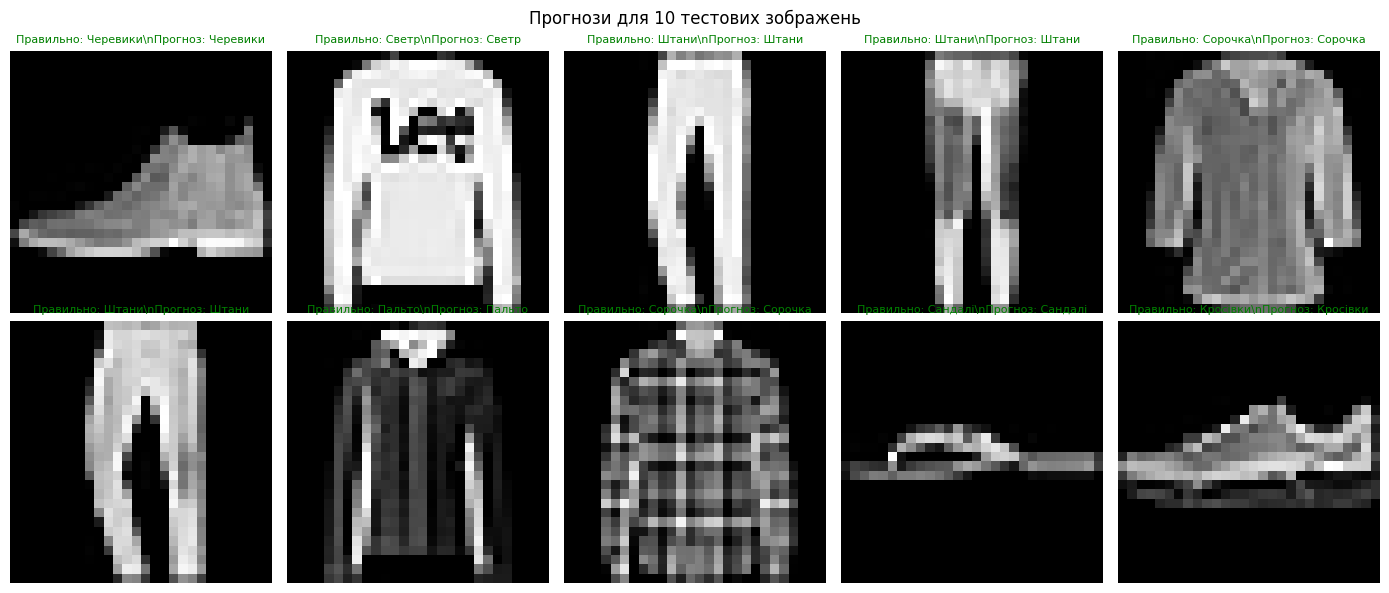

In [11]:
sample_indices = np.arange(10)
sample_probs = model.predict(x_test[sample_indices], verbose=0)
sample_preds = np.argmax(sample_probs, axis=1)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, idx, pred in zip(axes.flat, sample_indices, sample_preds):
    true_label = int(y_test[idx])
    correct = true_label == int(pred)
    ax.imshow(x_test[idx], cmap="gray")
    ax.set_title(
        f"Правильно: {class_names[true_label]}\\nПрогноз: {class_names[int(pred)]}",
        color="green" if correct else "red",
        fontsize=8
    )
    ax.axis("off")
plt.suptitle("Прогнози для 10 тестових зображень")
plt.tight_layout()
plt.show()


**Проміжний висновок до завдання 1**

Після виконання комірки оцінювання вище фактична тестова точність зберігається у змінній `test_accuracy`. Кількість помилок для кожного класу наведена виводом комірки. Вимога лабораторної роботи вважається виконаною, якщо `test_accuracy >= 0.87`.



# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
%pip install -q keras-tuner

import keras_tuner as kt
from tensorflow.keras import regularizers
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.models import Sequential
print("Keras Tuner:", kt.__version__)


Keras Tuner: 1.4.8


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [13]:
x_tuner_train = x_train
y_tuner_train = y_train

print("Навчальні дані для пошуку:", x_tuner_train.shape, y_tuner_train.shape)
print("Окрема тестова вибірка:", x_test.shape, y_test.shape)


Навчальні дані для пошуку: (60000, 28, 28) (60000,)
Окрема тестова вибірка: (10000, 28, 28) (10000,)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [14]:
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(28, 28)))
    model.add(Flatten())

    num_layers = hp.Int("num_layers", min_value=1, max_value=3, step=1)
    for i in range(num_layers):
        units = hp.Int(f"units_{i}", min_value=32, max_value=512, step=32)
        dropout_rate = hp.Float(f"dropout_{i}", min_value=0.1, max_value=0.5, step=0.1)
        l2_value = hp.Choice("l2", values=[1e-5, 1e-4, 1e-3])
        model.add(Dense(
            units,
            activation="relu",
            kernel_regularizer=regularizers.l2(l2_value)
        ))
        model.add(Dropout(dropout_rate))

    learning_rate = hp.Choice("learning_rate", values=[0.01, 0.001, 0.0001])
    model.add(Dense(10, activation="softmax"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [15]:
tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective="val_accuracy",
    max_trials=3,
    executions_per_trial=1,
    directory="/content/keras_tuner_fashion",
    project_name="fashion_mnist_search",
    overwrite=True,
    seed=SEED
)
tuner.search_space_summary()


Search space summary
Default search space size: 5
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
dropout_0 (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
l2 (Choice)
{'default': 1e-05, 'conditions': [], 'values': [1e-05, 0.0001, 0.001], 'ordered': True}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [16]:
tuner_callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

tuner.search(
    x_tuner_train, y_tuner_train,
    epochs=15,
    batch_size=128,
    validation_split=0.2,
    callbacks=tuner_callbacks,
    verbose=1
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі гіперпараметри:")
for key, value in best_hp.values.items():
    print(f"{key}: {value}")

best_model = tuner.hypermodel.build(best_hp)
best_history = best_model.fit(
    x_tuner_train, y_tuner_train,
    epochs=20,
    batch_size=128,
    validation_split=0.2,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
    ],
    verbose=1
)
best_model.summary()


Trial 3 Complete [00h 00m 36s]
val_accuracy: 0.8656666874885559

Best val_accuracy So Far: 0.8678333163261414
Total elapsed time: 00h 02m 54s
Найкращі гіперпараметри:
num_layers: 2
units_0: 288
dropout_0: 0.1
l2: 0.0001
learning_rate: 0.01
units_1: 512
dropout_1: 0.4
Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.7526 - loss: 0.7995 - val_accuracy: 0.8251 - val_loss: 0.5820 - learning_rate: 0.0100
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.7978 - loss: 0.6377 - val_accuracy: 0.8382 - val_loss: 0.5227 - learning_rate: 0.0100
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8042 - loss: 0.6313 - val_accuracy: 0.8202 - val_loss: 0.5937 - learning_rate: 0.0100
Epoch 4/20
373/375 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8065 - loss: 0.6278
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.004999999888241291.
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8038 - loss: 0.6367 - val_accuracy: 0.8285 - val_loss: 

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 288)            │       226,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 512)            │       147,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,137,536 (4.34 MB)

 Trainable params: 379,178 (1.45 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 758,358 (2.89 MB)

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Налаштована модель — test loss: 0.4323
Налаштована модель — test accuracy: 0.8553


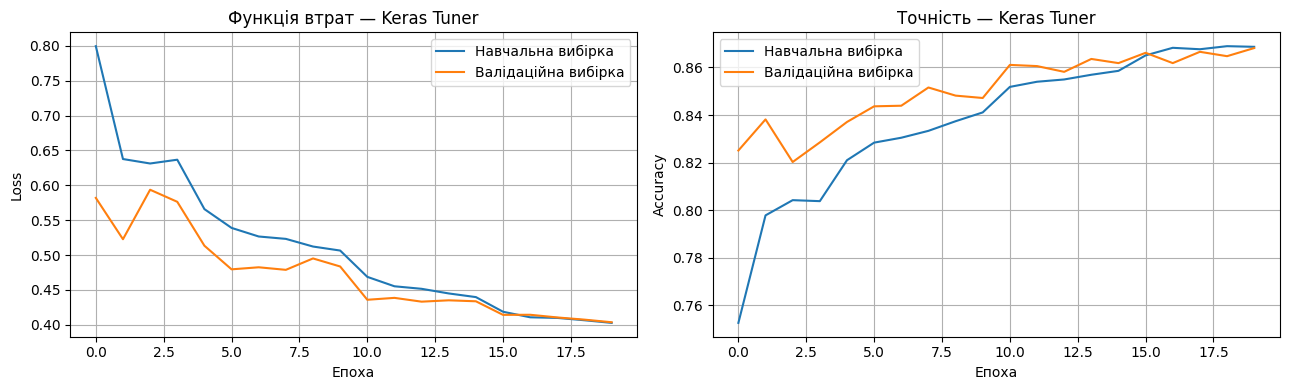

Налаштовану модель збережено: /content/fashion_mnist_tuned.keras


In [17]:
best_test_loss, best_test_accuracy = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Налаштована модель — test loss: {best_test_loss:.4f}")
print(f"Налаштована модель — test accuracy: {best_test_accuracy:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(best_history.history["loss"], label="Навчальна вибірка")
axes[0].plot(best_history.history["val_loss"], label="Валідаційна вибірка")
axes[0].set_title("Функція втрат — Keras Tuner")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(best_history.history["accuracy"], label="Навчальна вибірка")
axes[1].plot(best_history.history["val_accuracy"], label="Валідаційна вибірка")
axes[1].set_title("Точність — Keras Tuner")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

best_model.save("/content/fashion_mnist_tuned.keras")
print("Налаштовану модель збережено: /content/fashion_mnist_tuned.keras")


In [20]:
import pandas as pd
baseline_hidden_layers = 2
baseline_neurons = "256, 128"
tuned_layers = best_hp.get("num_layers")
tuned_neurons = ", ".join(str(best_hp.get(f"units_{i}")) for i in range(tuned_layers))

comparison = pd.DataFrame({
    "Показник": [
        "Кількість прихованих шарів",
        "Кількість нейронів",
        "Швидкість навчання",
        "Точність на тестовій вибірці (accuracy)",
        "Втрати на тестовій вибірці (loss)",
        "Кількість епох навчання"
    ],
    "Модель із завдання 1": [
        baseline_hidden_layers, baseline_neurons, 0.001,
        round(float(test_accuracy), 4), round(float(test_loss), 4), len(history.history["loss"])
    ],
    "Модель після Keras Tuner": [
        tuned_layers, tuned_neurons, best_hp.get("learning_rate"),
        round(float(best_test_accuracy), 4), round(float(best_test_loss), 4),
        len(best_history.history["loss"])
    ]
})
display(comparison)

print("\\nВИСНОВКИ:")
print(f"1. Точність базової моделі: {test_accuracy:.4f}. "
      + ("Вимогу 0.87 виконано." if test_accuracy >= 0.87 else "Вимогу 0.87 не виконано."))
delta = best_test_accuracy - test_accuracy
print(f"2. Зміна точності після налаштування: {delta:+.4f}.")
print(f"3. Найкраща конфігурація: {tuned_layers} прихованих шарів, "
      f"нейрони {tuned_neurons}, learning rate={best_hp.get('learning_rate')}.")
print("Результат може відрізнятися між запусками через випадкову ініціалізацію ваг, "
      "порядок навчання та обмежену кількість спроб RandomSearch.")
print("4. Найскладніші класи визначаються за кількістю помилок у матриці плутанини базової моделі; "
      "див. список, виведений у завданні 1.")


,Показник,Модель із завдання 1,Модель після Keras Tuner
0,Кількість прихованих шарів,2,2
1,Кількість нейронів,"256, 128","288, 512"
2,Швидкість навчання,0.001,0.01
3,Точність на тестовій вибірці (accuracy),0.8885,0.8553
4,Втрати на тестовій вибірці (loss),0.3195,0.4323
5,Кількість епох навчання,21,20


\nВИСНОВКИ:
1. Точність базової моделі: 0.8885. Вимогу 0.87 виконано.
2. Зміна точності після налаштування: -0.0332.
3. Найкраща конфігурація: 2 прихованих шарів, нейрони 288, 512, learning rate=0.01.
Результат може відрізнятися між запусками через випадкову ініціалізацію ваг, порядок навчання та обмежену кількість спроб RandomSearch.
4. Найскладніші класи визначаються за кількістю помилок у матриці плутанини базової моделі; див. список, виведений у завданні 1.


# Висновки. Порівняння моделей

У попередній комірці програма формує таблиці з фактичними показниками двох моделей і виводяться удачні результати.Також як видно з графіків у Keras Tuner функція втрат і тачність, показники навчальна вибірка і валідація за показниками з часом і епохами зрівнюються. А в тому графіку навчання що више навпаки, по середині епох сходяться але при кінці розходяться. Навчання моделі займало менше часу дес з одну минуту, чим пошук конфігурацій що тривала 5 минут.



---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.